In [7]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Automatically find project root
current = Path.cwd()
ROOT = current

while ROOT != ROOT.parent and not (ROOT / "backend").exists():
    ROOT = ROOT.parent

BACKEND = ROOT / "backend"

print("Project root:", ROOT)
print("Backend folder:", BACKEND)

# Load existing output files
als = pd.read_csv(BACKEND / "recommendations.csv")
graphx = pd.read_csv(BACKEND / "graphx_recommendations.csv")
popular = pd.read_csv(BACKEND / "popular_movies.csv")
evaluation = pd.read_csv(BACKEND / "evaluation_results.csv")
relationships = pd.read_csv(BACKEND / "user_movie_relationships.csv")

print("\nAll CSV files loaded successfully!")

for name, df in [
    ("ALS", als),
    ("GraphX", graphx),
    ("Popular Movies", popular),
    ("Evaluation", evaluation),
    ("User-Movie Relationships", relationships)
]:
    print(f"\n{name}: {df.shape}")
    print(df.columns.tolist())
    display(df.head(3))


Project root: c:\movie_recommend
Backend folder: c:\movie_recommend\backend

All CSV files loaded successfully!

ALS: (18860, 5)
['movieId', 'userId', 'predicted_rating', 'title', 'genres']


,movieId,userId,predicted_rating,title,genres
0,1217,471,5.273294,Assassins (1995),Thriller
1,1410,471,5.232631,Harlem (1993),Drama
2,1446,471,5.134329,"Bye Bye, Love (1995)",Comedy



GraphX: (47150, 3)
['userId', 'movieId', 'graph_score']


,userId,movieId,graph_score
0,809,814,5.0
1,809,1122,5.0
2,809,1189,5.0



Popular Movies: (1682, 5)
['movieId', 'total_ratings', 'average_rating', 'title', 'genres']


,movieId,total_ratings,average_rating,title,genres
0,50,583,4.358491,Star Wars (1977),Action|Adventure|Romance|Sci-Fi|War
1,258,509,3.803536,Contact (1997),Drama|Sci-Fi
2,100,508,4.155512,Fargo (1996),Crime|Drama|Thriller



Evaluation: (1, 15)
['Algorithm', 'Rank', 'MaxIter', 'RegParam', 'RMSE', 'MAE', 'Precision_at_10', 'Recall_at_10', 'Training_Time_Seconds', 'Prediction_Time_Seconds', 'Recommendation_Time_Seconds', 'Original_Records', 'Cleaned_Records', 'Training_Records', 'Testing_Records']


,Algorithm,Rank,MaxIter,RegParam,RMSE,MAE,Precision_at_10,Recall_at_10,Training_Time_Seconds,Prediction_Time_Seconds,Recommendation_Time_Seconds,Original_Records,Cleaned_Records,Training_Records,Testing_Records
0,ALS,10,10,0.1,0.926681,0.73429,0.017448,0.015929,11.519395,8.183567,5.970801,100000,100000,80049,19951



User-Movie Relationships: (100000, 4)
['userId', 'movieId', 'title', 'rating']


,userId,movieId,title,rating
0,59,196,Dead Poets Society (1989),5.0
1,42,96,Terminator 2: Judgment Day (1991),5.0
2,189,526,Ben-Hur (1959),4.0


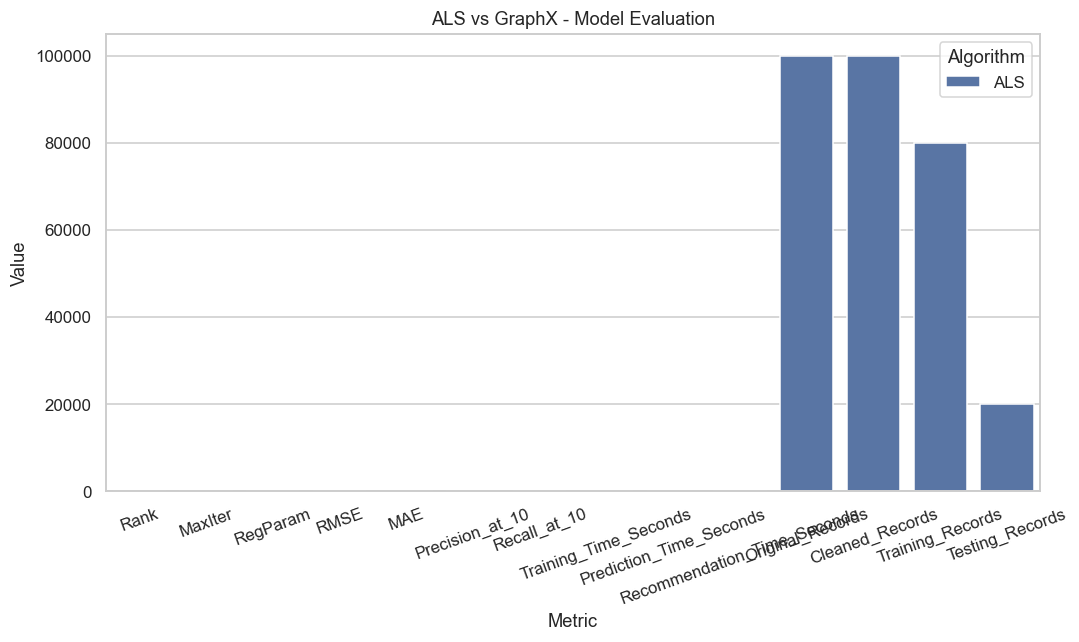

In [8]:

# CHART 1: Model Evaluation Comparison

model_col = next(
    (c for c in evaluation.columns
     if c.lower() in ["model", "algorithm", "method", "approach"]),
    None
)

if model_col:
    metric_cols = [
        c for c in evaluation.select_dtypes(include="number").columns
        if c != model_col
    ]

    if metric_cols:
        plot_data = evaluation.melt(
            id_vars=model_col,
            value_vars=metric_cols,
            var_name="Metric",
            value_name="Value"
        )

        plt.figure(figsize=(10, 6))
        sns.barplot(
            data=plot_data,
            x="Metric",
            y="Value",
            hue=model_col
        )
        plt.title("ALS vs GraphX - Model Evaluation")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()
    else:
        print("No numeric evaluation metrics found.")
else:
    print("No model/algorithm column found in evaluation_results.csv")


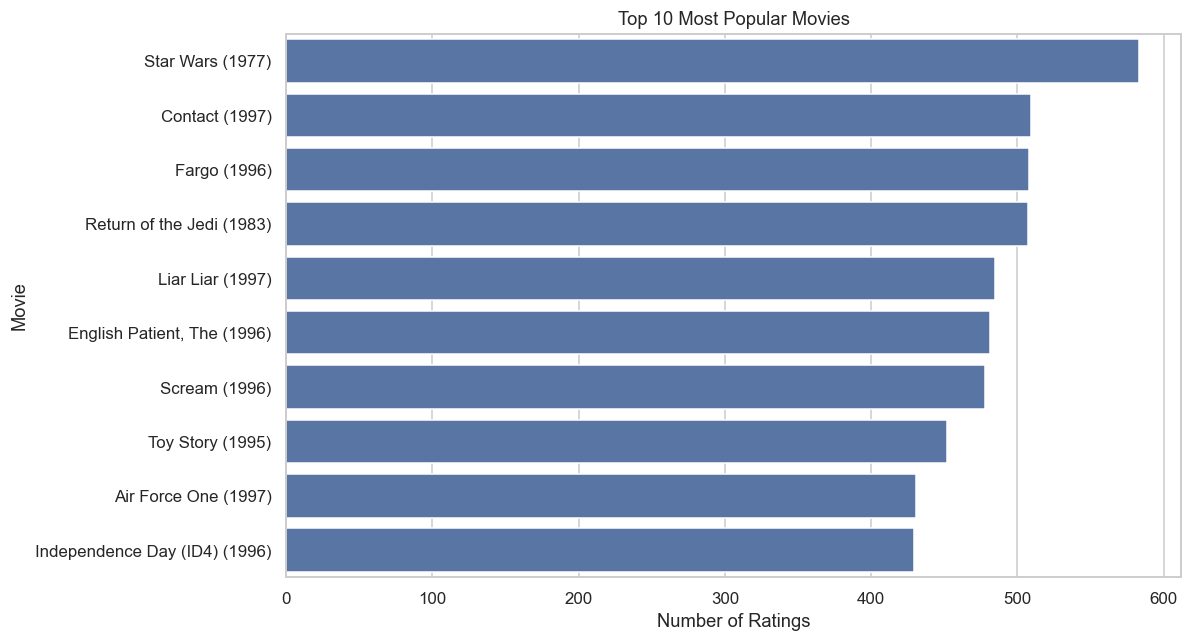

In [9]:

# CHART 2: Top 10 Popular Movies

title_col = next(
    (c for c in popular.columns
     if c.lower() in ["title", "movie_title", "name"]),
    None
)

count_col = next(
    (c for c in popular.columns
     if c.lower() in [
         "rating_count", "ratings_count", "count",
         "num_ratings", "popularity", "total_ratings"
     ]),
    None
)

if title_col and count_col:
    top_movies = popular.nlargest(10, count_col)

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=top_movies,
        x=count_col,
        y=title_col
    )
    plt.title("Top 10 Most Popular Movies")
    plt.xlabel("Number of Ratings")
    plt.ylabel("Movie")
    plt.tight_layout()
    plt.show()
else:
    print("Could not detect movie title and rating-count columns.")


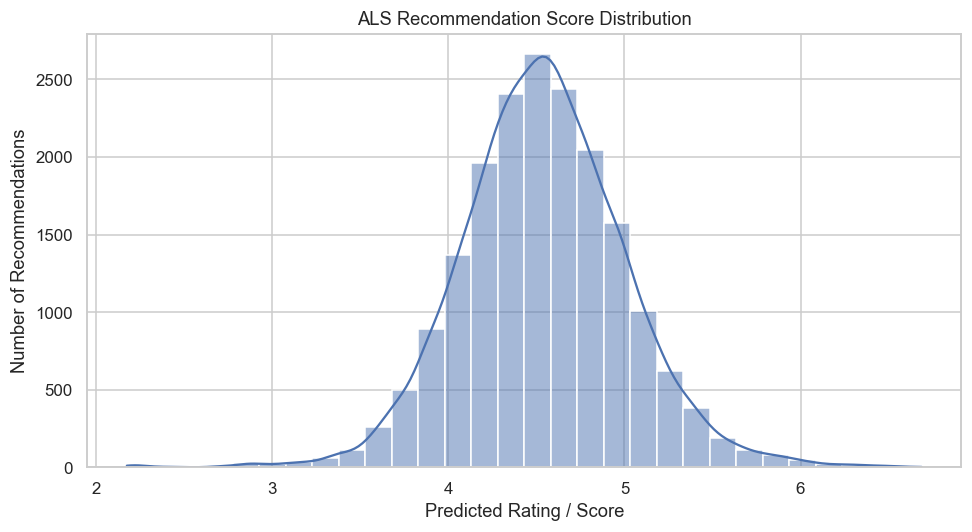

In [10]:

# CHART 3: ALS Score Distribution

als_score_col = next(
    (c for c in als.columns
     if c.lower() in [
         "predicted_rating", "prediction", "rating",
         "score", "als_score"
     ]),
    None
)

if als_score_col:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        als[als_score_col].dropna(),
        bins=30,
        kde=True
    )
    plt.title("ALS Recommendation Score Distribution")
    plt.xlabel("Predicted Rating / Score")
    plt.ylabel("Number of Recommendations")
    plt.tight_layout()
    plt.show()
else:
    print("No ALS score column found.")


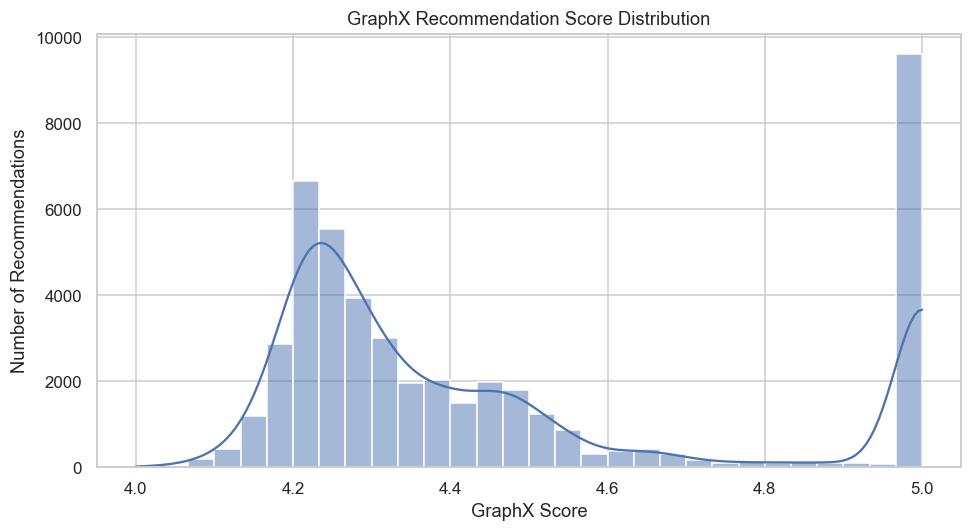

In [11]:

# CHART 4: GraphX Score Distribution

graphx_score_col = next(
    (c for c in graphx.columns
     if c.lower() in [
         "graph_score", "score", "prediction",
         "rating", "graphx_score"
     ]),
    None
)

if graphx_score_col:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        graphx[graphx_score_col].dropna(),
        bins=30,
        kde=True
    )
    plt.title("GraphX Recommendation Score Distribution")
    plt.xlabel("GraphX Score")
    plt.ylabel("Number of Recommendations")
    plt.tight_layout()
    plt.show()
else:
    print("No GraphX score column found.")


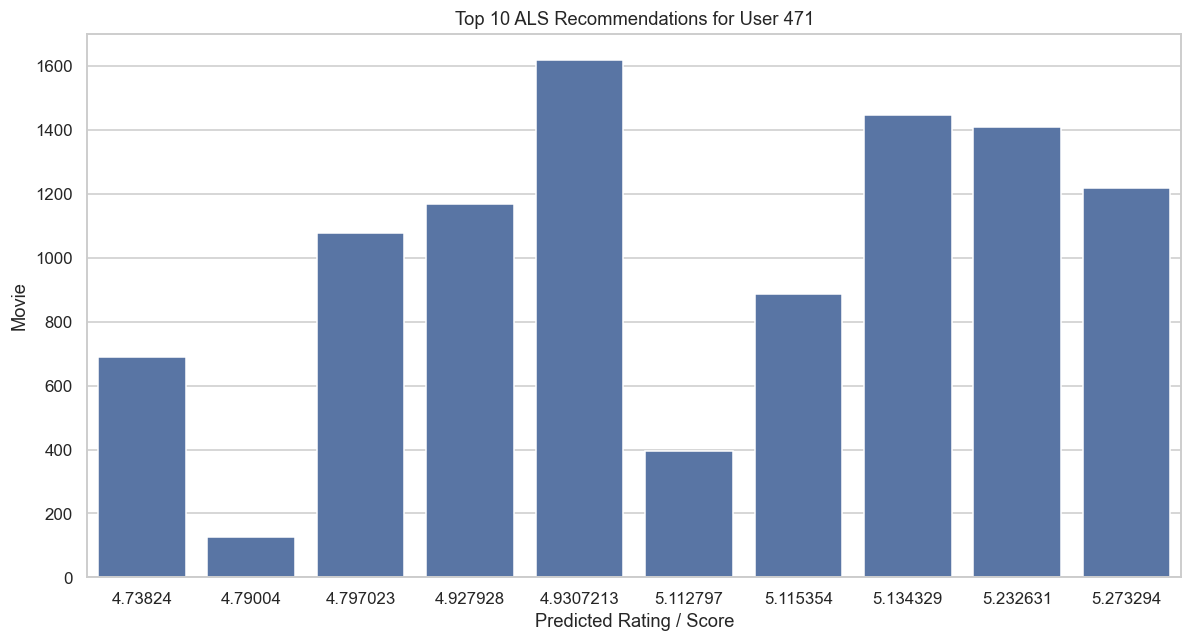

In [12]:

# CHART 5: Top 10 ALS Recommendations for One User

user_col = next(
    (c for c in als.columns if c.lower() in ["userid", "user_id"]),
    None
)

movie_col_als = next(
    (c for c in als.columns
     if c.lower() in ["title", "movie_title", "movieid", "movie_id"]),
    None
)

if als_score_col and user_col and movie_col_als:
    selected_user = als[user_col].iloc[0]

    user_recs = als[als[user_col] == selected_user]
    top_als = user_recs.nlargest(10, als_score_col)

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=top_als,
        x=als_score_col,
        y=movie_col_als
    )
    plt.title(f"Top 10 ALS Recommendations for User {selected_user}")
    plt.xlabel("Predicted Rating / Score")
    plt.ylabel("Movie")
    plt.tight_layout()
    plt.show()
else:
    print("Required ALS user, movie or score columns not found.")


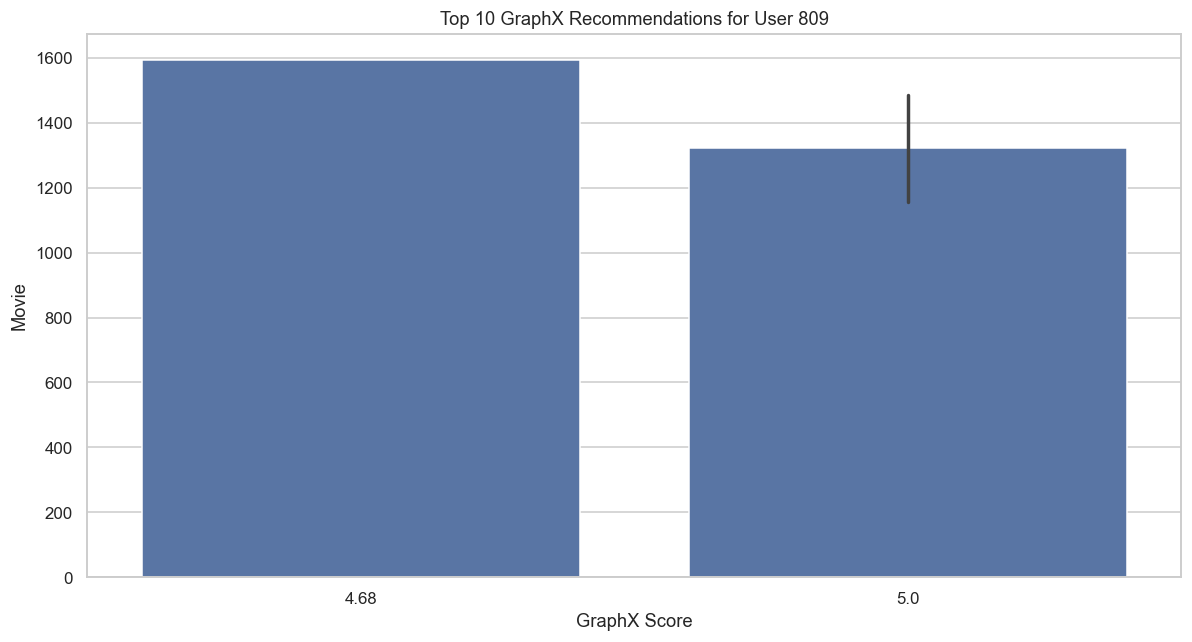

In [13]:

# CHART 6: Top 10 GraphX Recommendations for One User

graphx_user_col = next(
    (c for c in graphx.columns
     if c.lower() in ["userid", "user_id"]),
    None
)

graphx_movie_col = next(
    (c for c in graphx.columns
     if c.lower() in ["title", "movie_title", "movieid", "movie_id"]),
    None
)

if graphx_score_col and graphx_user_col and graphx_movie_col:
    selected_user = graphx[graphx_user_col].iloc[0]

    user_recs = graphx[
        graphx[graphx_user_col] == selected_user
    ]

    top_graphx = user_recs.nlargest(10, graphx_score_col)

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=top_graphx,
        x=graphx_score_col,
        y=graphx_movie_col
    )
    plt.title(f"Top 10 GraphX Recommendations for User {selected_user}")
    plt.xlabel("GraphX Score")
    plt.ylabel("Movie")
    plt.tight_layout()
    plt.show()
else:
    print("Required GraphX user, movie or score columns not found.")


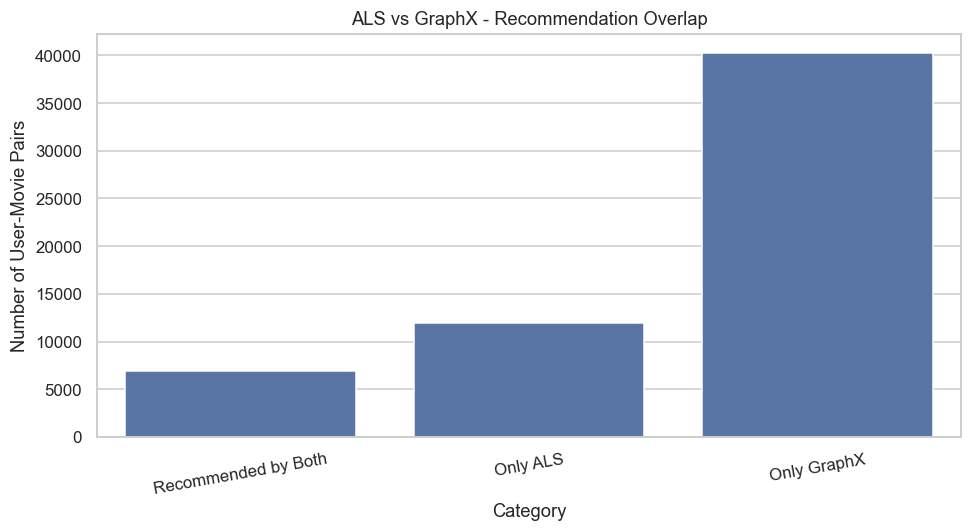

,Category,Count
0,Recommended by Both,6894
1,Only ALS,11966
2,Only GraphX,40256


In [14]:

# CHART 7: ALS vs GraphX Recommendation Overlap

als_user = next(
    (c for c in als.columns if c.lower() in ["userid", "user_id"]),
    None
)

als_movie = next(
    (c for c in als.columns if c.lower() in ["movieid", "movie_id"]),
    None
)

gx_user = next(
    (c for c in graphx.columns if c.lower() in ["userid", "user_id"]),
    None
)

gx_movie = next(
    (c for c in graphx.columns if c.lower() in ["movieid", "movie_id"]),
    None
)

if all([als_user, als_movie, gx_user, gx_movie]):
    als_pairs = set(zip(als[als_user], als[als_movie]))
    graphx_pairs = set(zip(graphx[gx_user], graphx[gx_movie]))

    common = len(als_pairs & graphx_pairs)
    only_als = len(als_pairs - graphx_pairs)
    only_graphx = len(graphx_pairs - als_pairs)

    overlap = pd.DataFrame({
        "Category": [
            "Recommended by Both",
            "Only ALS",
            "Only GraphX"
        ],
        "Count": [common, only_als, only_graphx]
    })

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=overlap,
        x="Category",
        y="Count"
    )
    plt.title("ALS vs GraphX - Recommendation Overlap")
    plt.ylabel("Number of User-Movie Pairs")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

    display(overlap)
else:
    print("User ID and Movie ID columns are required in both files.")


NameError: name 'save_chart' is not defined

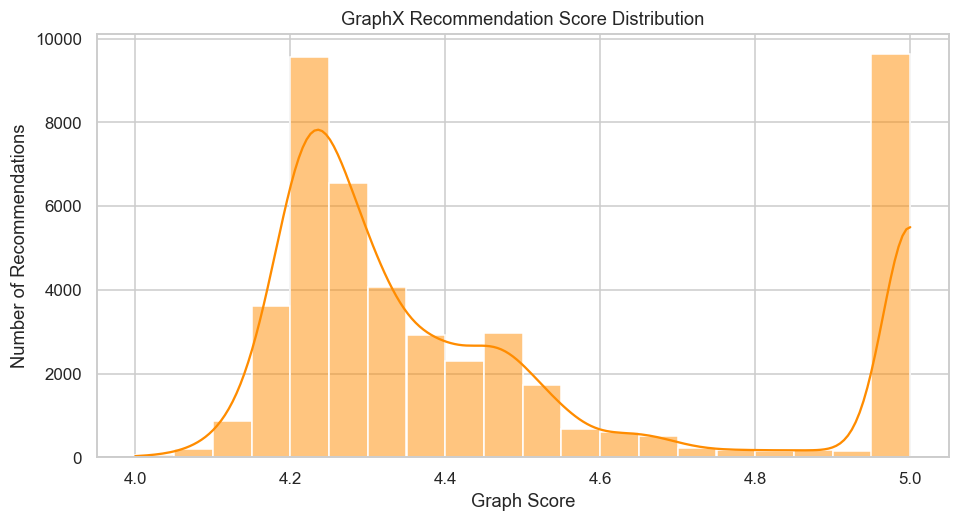

In [15]:

if "graph_score" in graphx.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        graphx["graph_score"].dropna(),
        bins=20,
        kde=True,
        color="darkorange"
    )

    plt.title("GraphX Recommendation Score Distribution")
    plt.xlabel("Graph Score")
    plt.ylabel("Number of Recommendations")

    save_chart("09_graphx_score_distribution.png")
else:
    print("graph_score column not found.")
